# Week 5a.1: Retrieval

The support agent answers policy questions out of `search_faq`, which is a dictionary with four entries in it. That worked because we wrote both the questions and the answers.

Real policies are documents. Husky Tech's runs to four sections covering returns, shipping, warranty and support hours, and the useful parts of it are sentences buried inside paragraphs. We cannot put a document in a prompt and we cannot write a dictionary entry for every question a customer might ask.

What we'll do instead is give the agent a way to look things up: split the document into pieces, store those pieces so they can be searched by meaning rather than by keyword, and retrieve the few that bear on the question. In other words, we'll add a RAG component to our agent.

- https://docs.langchain.com/oss/python/langchain/retrieval


### RAG Steps
- Ingest the knowledgebase
    - Load the docs
    - Chunk the docs
    - Embed the chunks
    - Store chunk embeddings in a vector store

- Retrieve the relevant chunks
    - Query the vector store with the user question
    - Get the matching chunks
    - Insert them into the prompt
    - Feed the augmented prompt into the model

In [1]:
from dotenv import load_dotenv
import os

load_dotenv()
assert os.getenv("GOOGLE_API_KEY"), "No GOOGLE_API_KEY found."
print("API key loaded")

API key loaded


## 0. Model Setup

Execute one of the following to define the model.

In [12]:
from langchain_ollama import ChatOllama

model = ChatOllama(model="qwen3.5:4b", reasoning=False)

In [ ]:
from langchain.chat_models import init_chat_model

model = init_chat_model(model="gpt-4.1-mini")

In [13]:
from langchain_google_genai import ChatGoogleGenerativeAI

model = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")

## 1. Loading Documents

`husky_policy.md` is the written policy we'll use for the RAG example.

LangChain provides various document loader integrations:
- https://docs.langchain.com/oss/python/integrations/document_loaders


In [4]:
policy_text = open("husky_policy.md").read()

print(f"{len(policy_text)} characters\n")
print(policy_text)

2038 characters

# Husky Tech Customer Policy

## 1. Returns

### 1.1 Standard return window

Items purchased from Husky Tech may be returned within 30 days of delivery for a
full refund to the original payment method. The item must be in its original
packaging with all included accessories. Refunds are issued within 5 business
days of the returned item arriving at our warehouse.

Return shipping is free for orders over $50. For orders under $50, a $6.99
return shipping fee is deducted from the refund.

### 1.2 Items that cannot be returned

Opened software, digital download codes, and redeemed gift cards are not
returnable under any circumstances. Earbuds and in-ear headphones may only be
returned if the hygiene seal is unbroken.

### 1.3 Damaged, defective, and dead-on-arrival items

The 30-day window described in section 1.1 does not apply to items that arrive
damaged or that fail due to a manufacturing defect. Such items may be returned
at any point during the one-year manufacturer

Notice section 1.3. It does not restate the return window; it says *"The 30-day window described in section 1.1 does not apply..."*. Policies are written like this, because a human reading the document can see section 1.1 a few lines above.

## 2. Splitting

It's not feasible to put the entire set of docs into the context window.

Instead, we'll split the document into chunks and retrieve only the ones that matter for the query, which we'll then feed into the model.

LangChain provides various integrations for text splitting:
- https://docs.langchain.com/oss/python/integrations/splitters

`RecursiveCharacterTextSplitter` tries to break on paragraph boundaries first, then lines, then words, so that chunks end at natural places rather than mid-sentence.
- **chunk_size** determines the number of characters
- **chunk_overlap** specifies the amount of overlapping characters between the chunks
- **split_text()** is used to split the document with the splitter.

In [6]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

splitter = RecursiveCharacterTextSplitter(chunk_size=400, chunk_overlap=0) 
chunks = splitter.split_text(policy_text)

print(f"{len(chunks)} chunks\n")
for i, c in enumerate(chunks):
    print(f"--- chunk {i} ({len(c)} chars)")
    print(c.strip()[:200], "\n")

6 chunks

--- chunk 0 (365 chars)
# Husky Tech Customer Policy

## 1. Returns

### 1.1 Standard return window

Items purchased from Husky Tech may be returned within 30 days of delivery for a
full refund to the original payment method 

--- chunk 1 (356 chars)
Return shipping is free for orders over $50. For orders under $50, a $6.99
return shipping fee is deducted from the refund.

### 1.2 Items that cannot be returned

Opened software, digital download co 

--- chunk 2 (341 chars)
### 1.3 Damaged, defective, and dead-on-arrival items

The 30-day window described in section 1.1 does not apply to items that arrive
damaged or that fail due to a manufacturing defect. Such items may 

--- chunk 3 (343 chars)
Customers reporting damage should be asked for the order number and a short
description of the fault. No photograph is required.

## 2. Shipping

Standard shipping takes 3 to 5 business days within th 

--- chunk 4 (343 chars)
Orders placed after 2pm ET ship the following business day

Read chunk 0 and chunk 2 next to each other.

Chunk 0 contains the 30-day rule. Chunk 2 contains the exception to it, and refers to "section 1.1" to do so. They are now two separate pieces of text, and nothing connects them.

Hold on to that. It matters more than it looks, and we come back to it on Friday.


## 3. Embeddings

To search by meaning we need meaning as a number. An **embedding model** turns a piece of text into a vector, positioned so that texts about similar things land near each other.

LangChain provides various integrations for embedding models:
- https://docs.langchain.com/oss/python/integrations/embeddings


In [16]:
from langchain_google_genai import GoogleGenerativeAIEmbeddings

embeddings = GoogleGenerativeAIEmbeddings(model="models/gemini-embedding-001")

### Ollama: Qwen3 Embedding Model
Download the embedding model 
- https://ollama.com/library/qwen3-embedding

Run `ollama pull qwen3-embedding:0.6b` in the terminal

In [8]:
from langchain_ollama import OllamaEmbeddings

embeddings = OllamaEmbeddings(model="qwen3-embedding:0.6b")

### OpenRouter: Liquid LFM embedding

OpenRouter serves embeddings on an OpenAI-compatible endpoint, so the OpenAI client
works against it once you point it at their base URL. Add `OPENROUTER_API_KEY` to
your `.env`.

Note `check_embedding_ctx_length=False`. Left at its default, LangChain counts tokens
with OpenAI's tokenizer before sending, which this model rejects with a 400.

In [9]:
from langchain_openai import OpenAIEmbeddings

embeddings = OpenAIEmbeddings(
    model="liquid/lfm-2.5-embedding-350m:free",
    base_url="https://openrouter.ai/api/v1",
    api_key=os.environ["OPENROUTER_API_KEY"],
    check_embedding_ctx_length=False,
)

KeyError: 'OPENROUTER_API_KEY'

### NVIDIA: Nemotron embedding

`nvidia/nemotron-3-embed-1b` runs on NVIDIA's hosted endpoint. Add `NVIDIA_API_KEY`
to your `.env`.

In [10]:
from langchain_nvidia_ai_endpoints import NVIDIAEmbeddings

embeddings = NVIDIAEmbeddings(model="nvidia/nemotron-3-embed-1b")

/Users/Teoman/Desktop/Classes/NU/Fall26/Agentic/Agentic-AI/.venv/lib/python3.13/site-packages/langchain_nvidia_ai_endpoints/_common.py:212: UserWarning: An API key is required for the hosted NIM. This will become an error in the future.
  warnings.warn(
/Users/Teoman/Desktop/Classes/NU/Fall26/Agentic/Agentic-AI/.venv/lib/python3.13/site-packages/langchain_nvidia_ai_endpoints/_common.py:250: UserWarning: Found nvidia/nemotron-3-embed-1b in available_models, but type is unknown and inference may fail.
  warnings.warn(


In [11]:
v = embeddings.embed_query("Can I return a damaged item?")
print(f"a vector of {len(v)} numbers")
print(v[:8], "...")

Exception: [401] Unauthorized
Authentication failed
Please check or regenerate your API key.

The numbers mean nothing on their own. 

What matters is distance, which will be our measure of similarity between two vectors.

Here is a simple cosine similarity function:

In [17]:
import numpy as np

def similarity(x, y):
    x, y = np.array(x), np.array(y)
    return float(x @ y / (np.linalg.norm(x) * np.linalg.norm(y)))

In [18]:
a = embeddings.embed_query("Can I return a damaged item?")
b = embeddings.embed_query("My headphones arrived broken, can I send them back?")
c = embeddings.embed_query("What time does support close on Friday?")

In [19]:
len(a), len(b), len(c)

(3072, 3072, 3072)

In [20]:
print(f"damaged item   vs  arrived broken : {similarity(a, b):.3f}")
print(f"damaged item   vs  support hours  : {similarity(a, c):.3f}")

damaged item   vs  arrived broken : 0.779
damaged item   vs  support hours  : 0.544


The two return questions score higher than the return question against the support-hours question, and they share no important words. That is the whole idea: the match is on meaning, not on vocabulary.

## 4. Embedding the documents

So far we have embedded three sentences we typed by hand. The policy itself has not been embedded at all.

We'll now embed the policy document using the embedding model.
 - `embed_query` takes one string, which is what a question is. 
 - `embed_documents` takes the whole list, which is what a corpus is. 

**The document and queries need to be embedded using the same model, because vectors from two different models cannot be compared.**

In [21]:
chunks

['# Husky Tech Customer Policy\n\n## 1. Returns\n\n### 1.1 Standard return window\n\nItems purchased from Husky Tech may be returned within 30 days of delivery for a\nfull refund to the original payment method. The item must be in its original\npackaging with all included accessories. Refunds are issued within 5 business\ndays of the returned item arriving at our warehouse.',
 'Return shipping is free for orders over $50. For orders under $50, a $6.99\nreturn shipping fee is deducted from the refund.\n\n### 1.2 Items that cannot be returned\n\nOpened software, digital download codes, and redeemed gift cards are not\nreturnable under any circumstances. Earbuds and in-ear headphones may only be\nreturned if the hygiene seal is unbroken.',
 '### 1.3 Damaged, defective, and dead-on-arrival items\n\nThe 30-day window described in section 1.1 does not apply to items that arrive\ndamaged or that fail due to a manufacturing defect. Such items may be returned\nat any point during the one-year m

In [22]:
# TODO: get the vectors for the chunks
vectors = embeddings.embed_documents(chunks)


print(f"{len(chunks)} chunks -> {len(vectors)} vectors of {len(vectors[0])} numbers each")

6 chunks -> 6 vectors of 3072 numbers each


In [23]:
type(vectors)

list

In [24]:
len(vectors)

6

In [25]:
vectors[0][:5]

[-0.011862011, 0.012105148, 0.019817496, -0.058291193, 0.007469076]

That is the expensive step, and it runs **once**, when the document changes. Every question after it only embeds the question.


## 5. Storing the documents
A vector store holds the chunks and their vectors and answers "which of these is closest?". 

`InMemoryVectorStore` keeps everything in a Python list. It disappears when the kernel stops, which is fine for a notebook but not acceptable for an application.

`from_texts` does the embedding above for you, which is why you will not usually see `embed_documents` written out.
 - `from_text(chunks, embeddings)`



In [29]:
from langchain_core.vectorstores import InMemoryVectorStore

# TODO create the vector store
store = InMemoryVectorStore.from_texts(chunks, embeddings)


In [30]:
type(store)

langchain_core.vectorstores.in_memory.InMemoryVectorStore

### store.store.items()
- A database containing the id, the embedding vector, and the content for the chunk.

In [31]:
for item in store.store.items():
    print(item[1]["id"])
    print(item[1]["vector"][:3])
    print(item[1]["text"][:50])
    print()

fa6d7df5-d785-4d98-99b8-fd9e48a892da
[-0.011862011, 0.012105148, 0.019817496]
# Husky Tech Customer Policy

## 1. Returns

### 1

95aef619-1bf2-4ae0-bdbf-ee06ae6adf54
[0.004746217, 0.008477623, 0.009311427]
Return shipping is free for orders over $50. For o

3a8839ed-2686-4961-bd75-8d55b3571a6d
[-0.01307962, 0.010974775, 0.007326525]
### 1.3 Damaged, defective, and dead-on-arrival it

d589a309-8d67-4690-ad4d-f96ce49ab72e
[-0.006569633, 0.014531255, 0.009021968]
Customers reporting damage should be asked for the

261db2eb-1fbd-49bd-b53d-5567188b99bf
[-0.0036559459, 0.0126460055, 0.008269717]
Orders placed after 2pm ET ship the following busi

23e9119d-10f1-4fc1-9fbd-a9176da8575a
[-0.006046255, 0.014195052, 0.013019427]
Warranty claims require the order number. Replacem



### Querying the vector store

`similarity_search()` allows you to query the vector store with a given string.
- First, the query is embedded using the embeddings model specified in from_texts()
- `k` specifies the number of chunks to return

In [32]:
hits = store.similarity_search("how long does shipping take?", k=2)
for h in hits:
    print("-", " ".join(h.page_content.split())[:110], "\n")

- Customers reporting damage should be asked for the order number and a short description of the fault. No photo 

- Orders placed after 2pm ET ship the following business day. Orders placed on a weekend ship on the next Monday 



In [33]:
hits

[Document(id='d589a309-8d67-4690-ad4d-f96ce49ab72e', metadata={}, page_content='Customers reporting damage should be asked for the order number and a short\ndescription of the fault. No photograph is required.\n\n## 2. Shipping\n\nStandard shipping takes 3 to 5 business days within the continental United\nStates. Expedited shipping arrives in 1 to 2 business days for $14.99. We do not\ncurrently ship outside the United States.'),
 Document(id='261db2eb-1fbd-49bd-b53d-5567188b99bf', metadata={}, page_content='Orders placed after 2pm ET ship the following business day. Orders placed on a\nweekend ship on the next Monday.\n\n## 3. Warranty\n\nAll Husky Tech electronics include a one-year manufacturer warranty covering\ndefects in materials and workmanship. The warranty does not cover accidental\ndamage, liquid damage, or normal wear such as frayed cables.')]

In [34]:
hits[0].page_content.strip()

'Customers reporting damage should be asked for the order number and a short\ndescription of the fault. No photograph is required.\n\n## 2. Shipping\n\nStandard shipping takes 3 to 5 business days within the continental United\nStates. Expedited shipping arrives in 1 to 2 business days for $14.99. We do not\ncurrently ship outside the United States.'

## 6. Retrieval as a tool

The agent needs this as a tool it can call. Note what the tool returns: the text of the chunks, not an answer. The retrieval step finds evidence, and the model does the reasoning.

In [65]:
from langchain.tools import tool

@tool
def search_policy(question: str) -> str:
    """Search the Husky Tech written policy and return the passages most relevant
    to a question. Use this for any question about returns, shipping, warranty or
    support hours. Returns policy text, not an answer: read it and decide."""
    
    #TODO: get the hits from the vector store for the question with k=2
    hits = store.similarity_search(question, k=2)

    
    if not hits:
        return "Nothing in the policy matched that question."
    return "\n\n---\n\n".join(h.page_content.strip() for h in hits)

In [36]:
print(search_policy.invoke({"question": "do you ship to Canada?"}))

Customers reporting damage should be asked for the order number and a short
description of the fault. No photograph is required.

## 2. Shipping

Standard shipping takes 3 to 5 business days within the continental United
States. Expedited shipping arrives in 1 to 2 business days for $14.99. We do not
currently ship outside the United States.

---

Orders placed after 2pm ET ship the following business day. Orders placed on a
weekend ship on the next Monday.

## 3. Warranty

All Husky Tech electronics include a one-year manufacturer warranty covering
defects in materials and workmanship. The warranty does not cover accidental
damage, liquid damage, or normal wear such as frayed cables.


## 7. The agent with retrieval

Same graph as W04b. The only change is the tool list: `search_policy` replaces `search_faq`, and everything else stays exactly as it was.

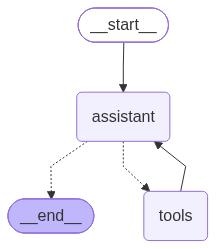

In [39]:
from support_tools import look_up_order, check_return_eligibility, escalate_to_human, SYSTEM_PROMPT
from langchain.messages import SystemMessage, HumanMessage
from langgraph.checkpoint.memory import InMemorySaver

from langgraph.graph import StateGraph, MessagesState, START, END
from langgraph.prebuilt import ToolNode, tools_condition
from IPython.display import Image, display


sys_msg = SystemMessage(content=SYSTEM_PROMPT)
TOOLS = [look_up_order, check_return_eligibility, search_policy, escalate_to_human]
model_with_tools = model.bind_tools(TOOLS)

def assistant(state: MessagesState) -> dict:
    return {"messages": [model_with_tools.invoke([sys_msg] + state["messages"])]}

#TODO: build the graph
builder = StateGraph(MessagesState)
builder.add_node("assistant", assistant)
builder.add_node("tools", ToolNode(TOOLS))
builder.add_edge(START, "assistant")
builder.add_conditional_edges("assistant", tools_condition)
builder.add_edge("tools", "assistant")


#TODO: create the support_agent
support_agent = builder.compile(checkpointer=InMemorySaver())



display(Image(support_agent.get_graph().draw_mermaid_png()))

It answers policy questions now, from a document nobody wrote a dictionary entry for:

In [40]:
config = {"configurable": {"thread_id": "customer-1"}}

for q in ["How long does standard shipping take?",
          "Can I return opened software?",
          "What does the warranty cover?"]:
    result = support_agent.invoke({"messages": [HumanMessage(content=q)]}, config)
    print(f"Q: {q}")
    print(f"A: {result['messages'][-1].text.strip()[:200]}\n")

Q: How long does standard shipping take?
A: Standard shipping takes 3 to 5 business days within the continental United States. Orders placed after 2 PM ET ship the following business day, and weekend orders ship on the next Monday.

Q: Can I return opened software?
A: I have connected you with a human support agent (ticket ESC-1042) to help answer your question about returning opened software, as that specific detail isn't currently listed in our standard policy do

Q: What does the warranty cover?
A: All Husky Tech electronics include a one-year manufacturer warranty covering defects in materials and workmanship. Please note that the warranty does not cover accidental damage, liquid damage, or nor



## 8. Using a real vector store: Pinecone

`InMemoryVectorStore` has done everything we asked of it, and it has one property
that rules it out for anything real. It is a Python dictionary. When the kernel
stops the index is gone, rebuilding it means paying to embed every chunk again, and
nothing outside this process can read it. The indexing job and the agent are stuck
living in the same notebook.

A managed vector database addresses these limitations. The index sits on a server, it persists,
and anything holding the API key can query it.

We'll use Pinecone. The free tier is more than enough for this course.
- https://docs.langchain.com/oss/python/integrations/vectorstores/pinecone

**Setup**

1. `uv pip install langchain-pinecone`
2. Make an account at [pinecone.io](https://www.pinecone.io) and create an API key
3. Add `PINECONE_API_KEY=...` to your `.env`, next to the keys you already have

In [49]:
load_dotenv()
assert os.getenv("PINECONE_API_KEY"), "No PINECONE_API_KEY found in .env"
print("Pinecone key loaded")

Pinecone key loaded


### The index has a fixed width

An index is created with a number of dimensions, and every vector you put in it has
to be exactly that wide. That number comes from the embedding model you picked in
section 3. Gemini returns 3072 numbers and `qwen3-embedding:0.6b` returns 1024, so
the two are not interchangeable.

Rather than hardcode it, ask the model. This is the same fact from section 4 in a
place where it has consequences: the width belongs to the model, not to the text.

In [50]:
dimension = len(embeddings.embed_query("a probe to measure the width"))
index_name = f"husky-policy-{dimension}"

print(f"{index_name}  ->  {dimension} dimensions")

husky-policy-3072  ->  3072 dimensions


### Accessing the index


In [51]:
from pinecone import Pinecone

pc = Pinecone(api_key=os.environ["PINECONE_API_KEY"])
index_name = "rag-demo"
index = pc.Index(index_name)

In [52]:
index.describe_index_stats()

{'dimension': 3072,
 'index_fullness': 0.0,
 'metric': 'cosine',
 'namespaces': {},
 'total_vector_count': 0,
 'vector_type': 'dense'}

### Putting the chunks in
The index exists and is empty. 

`metric="cosine"` has to match how you want nearness measured, and it is what our `similarity` function computed by hand in section 3. 

`dimension` has to match the model.

`add_texts` embeds each chunk and uploads it with its text attached, which is the indexing half of the RAG pipeline.
- This runs **once per document change**, not once per question. Writes take a moment
to become visible, so if the count below reads zero, run the stats cell again.

In [53]:
from langchain_pinecone import PineconeVectorStore

pinecone_store = PineconeVectorStore(index=index, embedding=embeddings)
pinecone_store.add_texts(chunks)

print(f"uploaded {len(chunks)} chunks")

uploaded 6 chunks


In [54]:
index.describe_index_stats()

{'dimension': 3072,
 'index_fullness': 0.0,
 'metric': 'cosine',
 'namespaces': {'': {'vector_count': 6}},
 'total_vector_count': 6,
 'vector_type': 'dense'}

### Searching the index

This is the same method call we made against `InMemoryVectorStore`.

In [55]:
hits = pinecone_store.similarity_search("how long does shipping take?", k=2)

for h in hits:
    print("-", " ".join(h.page_content.split())[:110], "\n")

- Customers reporting damage should be asked for the order number and a short description of the fault. No photo 

- Orders placed after 2pm ET ship the following business day. Orders placed on a weekend ship on the next Monday 



In [56]:
hits[0]

Document(id='d11bf9a9-ade8-40f6-885b-a1ffa2ce88b7', metadata={}, page_content='Customers reporting damage should be asked for the order number and a short\ndescription of the fault. No photograph is required.\n\n## 2. Shipping\n\nStandard shipping takes 3 to 5 business days within the continental United\nStates. Expedited shipping arrives in 1 to 2 business days for $14.99. We do not\ncurrently ship outside the United States.')

Note that `similarity_search(query, k)` is the same call with the same arguments returning the same objects, because both classes implement LangChain's `VectorStore` interface. 

The store behind it changed completely and the code asking the question did not change at all.

So the tool only needs one line altered.

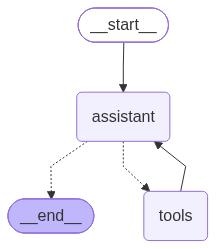

In [57]:
@tool
def search_policy(question: str) -> str:
    """Search the Husky Tech written policy and return the passages most relevant
    to a question. Use this for any question about returns, shipping, warranty or
    support hours. Returns policy text, not an answer: read it and decide."""
    hits = pinecone_store.similarity_search(question, k=2)      # <- the only change
    if not hits:
        return "Nothing in the policy matched that question."
    return "\n\n---\n\n".join(h.page_content.strip() for h in hits)


TOOLS = [look_up_order, check_return_eligibility, search_policy, escalate_to_human]
model_with_tools = model.bind_tools(TOOLS)

builder = StateGraph(MessagesState)
builder.add_node("assistant", assistant)
builder.add_node("tools", ToolNode(TOOLS))
builder.add_edge(START, "assistant")
builder.add_conditional_edges("assistant", tools_condition)
builder.add_edge("tools", "assistant")

support_agent = builder.compile(checkpointer=InMemorySaver())

display(Image(support_agent.get_graph().draw_mermaid_png()))

In [58]:
config = {"configurable": {"thread_id": "customer-2"}}

result = support_agent.invoke(
    {"messages": [HumanMessage(content="Can I return opened software?")]}, config)

print(result["messages"][-1].text)

No, opened software cannot be returned under any circumstances.


### What you have now that you did not have before

**It persists.** Restart the kernel and the index is still there with the chunks in
it. We don't have to embed the docs again.

**Anything can read it.** A deployed app, a scheduled job and this notebook can all
query the same index. Indexing and answering no longer have to be the same program.

**It filters.** Each record can carry metadata, and you can restrict a search to
records matching it. This is how a real system keeps one customer from retrieving
another customer's documents.

**It scales differently.** `InMemoryVectorStore` compares your question against every
vector it holds, which is exact and perfectly fine for six chunks. Pinecone uses an
approximate index, which gives up a little accuracy to stay fast at millions of
vectors.

## ICA

1. Rebuild the store with `chunk_size=1000`, then again with `chunk_size=200`. Print
   the chunks each time and ask the same three questions. Where do the retrieved
   passages start carrying text you did not ask about, and where do they start losing
   the sentence they needed?

2. Set `chunk_overlap=100` at the original size of 400. Compare the chunk boundaries
   against the run with no overlap. What does the overlap buy you, and what does it
   cost you inside a top-2 result?

3. `search_policy` asks for the 2 closest chunks. Try 1, 3 and 6 on "what are your
   support hours" and read what the model has to work through each time. Then say what
   you would set `k` to if you had to pick a single number that served every question
   a customer might ask.

4. Switch the embedding model in section 3, from Gemini to Ollama or back, and rerun
   section 7. You will find you need a new index. Explain why the existing one cannot
   be reused.

5. Ask three questions of your own that the policy does answer. Find one where the
   retrieved chunks are not the ones you would have chosen yourself, and work out
   whether the cause is the chunking, the embedding model, or the way the question was
   worded.

In [59]:
# your experiments here
QUESTIONS = ["How long does standard shipping take?",
             "Can I return opened software?",
             "What does the warranty cover?"]

for size in [1000, 200]:
    spliiter_exp = RecursiveCharacterTextSplitter(chunk_size=size, chunk_overlap=0)
    chunks_exp = spliiter_exp.split_text(policy_text)
    
    print(f"{len(chunks_exp)} chunks\n")
    for i, c in enumerate(chunks_exp):
        print(f"--- chunk {i} ({len(c)} chars)")
        print(c.strip(), "\n")

    
    store_exp = InMemoryVectorStore.from_texts(chunks_exp, embeddings)

    for q in QUESTIONS:
        print(f"Q: {q}")
        for h in store_exp.similarity_search(q, k=2):
            print("  -", " ".join(h.page_content.split()), "\n")



3 chunks

--- chunk 0 (778 chars)
# Husky Tech Customer Policy

## 1. Returns

### 1.1 Standard return window

Items purchased from Husky Tech may be returned within 30 days of delivery for a
full refund to the original payment method. The item must be in its original
packaging with all included accessories. Refunds are issued within 5 business
days of the returned item arriving at our warehouse.

Return shipping is free for orders over $50. For orders under $50, a $6.99
return shipping fee is deducted from the refund.

### 1.2 Items that cannot be returned

Opened software, digital download codes, and redeemed gift cards are not
returnable under any circumstances. Earbuds and in-ear headphones may only be
returned if the hygiene seal is unbroken.

### 1.3 Damaged, defective, and dead-on-arrival items 

--- chunk 1 (976 chars)
The 30-day window described in section 1.1 does not apply to items that arrive
damaged or that fail due to a manufacturing defect. Such items may be returned
at 

In [60]:
# your experiments here
QUESTIONS = ["How long does standard shipping take?",
             "Can I return opened software?",
             "What does the warranty cover?"]

for size in [400]:
    spliiter_exp = RecursiveCharacterTextSplitter(chunk_size=size, chunk_overlap=100)
    chunks_exp = spliiter_exp.split_text(policy_text)
    
    print(f"{len(chunks_exp)} chunks\n")
    for i, c in enumerate(chunks_exp):
        print(f"--- chunk {i} ({len(c)} chars)")
        print(c.strip(), "\n")

    
    store_exp = InMemoryVectorStore.from_texts(chunks_exp, embeddings)

    for q in QUESTIONS:
        print(f"Q: {q}")
        for h in store_exp.similarity_search(q, k=2):
            print("  -", " ".join(h.page_content.split()), "\n")



6 chunks

--- chunk 0 (365 chars)
# Husky Tech Customer Policy

## 1. Returns

### 1.1 Standard return window

Items purchased from Husky Tech may be returned within 30 days of delivery for a
full refund to the original payment method. The item must be in its original
packaging with all included accessories. Refunds are issued within 5 business
days of the returned item arriving at our warehouse. 

--- chunk 1 (356 chars)
Return shipping is free for orders over $50. For orders under $50, a $6.99
return shipping fee is deducted from the refund.

### 1.2 Items that cannot be returned

Opened software, digital download codes, and redeemed gift cards are not
returnable under any circumstances. Earbuds and in-ear headphones may only be
returned if the hygiene seal is unbroken. 

--- chunk 2 (341 chars)
### 1.3 Damaged, defective, and dead-on-arrival items

The 30-day window described in section 1.1 does not apply to items that arrive
damaged or that fail due to a manufacturing defect. Such 

In [61]:
# your experiments here
q = "what are the support hours"

for k in [1, 3, 6]:
    print(f"========== k={k} ==========")
    hits = store.similarity_search(q, k=k)
    for h in hits:
        print("  -", " ".join(h.page_content.split()), "\n")
    print(f"total text the model has to read: {sum(len(h.page_content) for h in hits)} chars\n")


========== k=1 ==========
  - Warranty claims require the order number. Replacement units ship within 3 business days of a claim being approved. ## 4. Support hours Support is available Monday through Friday, 9am to 6pm Eastern Time. Messages received outside those hours are answered the next business day. 

total text the model has to read: 279 chars

========== k=3 ==========
  - Warranty claims require the order number. Replacement units ship within 3 business days of a claim being approved. ## 4. Support hours Support is available Monday through Friday, 9am to 6pm Eastern Time. Messages received outside those hours are answered the next business day. 

  - Customers reporting damage should be asked for the order number and a short description of the fault. No photograph is required. ## 2. Shipping Standard shipping takes 3 to 5 business days within the continental United States. Expedited shipping arrives in 1 to 2 business days for $14.99. We do not currently ship outside the Unit

In [63]:
#switch to ollama i used google before
from langchain_ollama import OllamaEmbeddings
from pinecone import ServerlessSpec

ollama_emb = OllamaEmbeddings(model="qwen3-embedding:0.6b")
print("Gemini width:", len(embeddings.embed_query("probe")))
print("Ollama width:", len(ollama_emb.embed_query("probe")))

try:
    PineconeVectorStore(index=index, embedding=ollama_emb).add_texts(chunks[:1])
except Exception as e:
    print("\nFailed:", str(e)[:300])


ollama_dim = len(ollama_emb.embed_query("probe"))
ollama_index_name = f"husky-policy-{ollama_dim}"

if not pc.has_index(ollama_index_name):
    pc.create_index(name=ollama_index_name, dimension=ollama_dim, metric="cosine",
                    spec=ServerlessSpec(cloud="aws", region="us-east-1"))

ollama_index = pc.Index(ollama_index_name)
ollama_store = PineconeVectorStore(index=ollama_index, embedding=ollama_emb)

if ollama_index.describe_index_stats()["total_vector_count"] == 0:
    ollama_store.add_texts(chunks)
    print(f"uploaded {len(chunks)} chunks to {ollama_index_name}")

for h in ollama_store.similarity_search("how long does shipping take?", k=2):
    print("-", " ".join(h.page_content.split())[:110], "\n")




Gemini width: 3072
Ollama width: 1024

Failed: (400)
Reason: Bad Request
HTTP response headers: HTTPHeaderDict({'Date': 'Tue, 06 Oct 2026 20:24:45 GMT', 'Content-Type': 'application/json', 'Content-Length': '104', 'Connection': 'keep-alive', 'x-pinecone-request-latency-ms': '66', 'x-envoy-upstream-service-time': '67', 'x-pinecone-response-durati
uploaded 6 chunks to husky-policy-1024
- Customers reporting damage should be asked for the order number and a short description of the fault. No photo 

- Warranty claims require the order number. Replacement units ship within 3 business days of a claim being appro 



In [66]:
my_questions = [
    "Can I talk to support on the weekend?",
    "If I place an order on Saturday, when will it ship?",
    "I spilled coffee on my keyboard, is that covered?",
]

for q in my_questions:
    print("Q:", q)
    results = store.similarity_search_with_score(q, k=2)
    for doc, score in results:
        chunk_number = chunks.index(doc.page_content)
        print("  chunk", chunk_number, "| score", round(score, 3))
        print("  ", " ".join(doc.page_content.split()))
    print()

Q: Can I talk to support on the weekend?
  chunk 5 | score 0.705
   Warranty claims require the order number. Replacement units ship within 3 business days of a claim being approved. ## 4. Support hours Support is available Monday through Friday, 9am to 6pm Eastern Time. Messages received outside those hours are answered the next business day.
  chunk 3 | score 0.639
   Customers reporting damage should be asked for the order number and a short description of the fault. No photograph is required. ## 2. Shipping Standard shipping takes 3 to 5 business days within the continental United States. Expedited shipping arrives in 1 to 2 business days for $14.99. We do not currently ship outside the United States.

Q: If I place an order on Saturday, when will it ship?
  chunk 3 | score 0.695
   Customers reporting damage should be asked for the order number and a short description of the fault. No photograph is required. ## 2. Shipping Standard shipping takes 3 to 5 business days within the co

**ICA 1:** With size 1000, each chunk mixes several topics, so the results include text I didn't ask about. The shipping question even got the support-hours chunk first. With size 200, the results are precise, but sentences get cut in half, for example the warranty rule is split across chunks 11 and 12.

**ICA 2:** Overlap 100 changed nothing: I got the same 6 chunks, because the splitter only overlaps whole paragraphs and every paragraph here is longer than 100 characters. In general, overlap keeps context across chunk borders, but the top-2 results can then repeat the same text.

**ICA 3:** k=1 already finds the support hours, k=3 adds about 70% unrelated text, and k=6 returns the whole policy. I would choose k=3, because some answers come 2nd (like the warranty question) or need two chunks together.

**ICA 4:** Gemini makes vectors with 3072 numbers and Ollama makes 1024, but a Pinecone index has a fixed size, so the upload failed and I needed a new index. Even with the same size it would not work, because each model has its own vector space, so their vectors can't be compared.

**ICA 5:** The coffee question did not find chunk 4, which says liquid damage is not covered. Rewording didn't help but chunk size 200 found it, so the cause is chunking: chunk 4 is half about shipping, so it doesn't match a warranty question well.